In [31]:
%pip install -q qiskit

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# Bonus Task — Grover's algorithm

As covered in one of the video lectures, Grover's algorithm is a quantum algorithm designed to find a marked item in an unstructured database consisting of $N$ items. Compared to classical search, Grover's algorithm provides a quadratic speedup, allowing us to find the marked item in $\mathcal{O}(\sqrt{N})$ time complexity.

Although we will not cover every element of Grover's algorithm in detail, the purpose of this exercise is to give a good overview of the essential building blocks of the algorithm.

**Tip**: For an intuitive understanding of Grover's algorithm, we highly recommend watching the video on Grover's algorithm by 3Blue1Brown https://www.youtube.com/watch?v=RQWpF2Gb-gU, as it provides visualizations of the mathematical operations involved in the algorithm.

## Problem formulation
Before starting to construct the algorithm itself, let us begin by defining the problem more formally.

We consider an unstructured database of $N = 2^n$ possible items, where each item can be represented by an $n$-bit string $\lvert x \rangle$, with $x \in \{0, 1, \dots, N - 1\}$. Among these items, there exists one (or a small number of) item(s) that satisfy a given condition defined by an *oracle* function:

$$
f(x) =
\begin{cases}
1, & \text{if } x \text{ fulfills the condition}, \\
0, & \text{otherwise.}
\end{cases}
$$

The condition could, for example, be...
* ... an equation, such as $x^2=4$,
* ... or a boolean formula on the individual bits, such as $(x_0 \lor x_1) \land (x_2 \lor x_0)$.

In our case we will assume that there is only one $x^*$ that fulfills the condition. That is, $f(x^*) = 1$, and $f(x) = 0 \text{ for all }  x\neq x^*$.

The condition on $x^\ast$ is often such that it is difficult to obtain $x^*$ just by manipulating the condition (as we would normally solve an equation). Instead the goal of Grover’s algorithm is to find the item $x^\ast$ by *searching* for it, that is, by evaluating $f(x)$ for different values of $x$.

In quantum computing terms, we denote the unknown target basis state as $\vert \phi\rangle = \vert x^*\rangle$. This is the state that we want a high probability of measuring at the end of Grover's algorithm. (Note that $x^*$ is often used in the classical setting while $\vert \phi\rangle$ is used in the quantum setting, but they essentially have the same meaning.)

Classically, identifying $x^\ast$ requires, on average, $\mathcal{O}(N/2)$ oracle queries, since we need to search through half of the database on average before we find $x^\ast$.

However, using a quantum computer, we do not need to query the oracle $f(x)$ on each input separately. Instead, we can call the equivalent of $f(x)$ for a superposition of values of $x$ at the same time. By exploiting such quantum parallelization, Grover’s algorithm lets us measure $\vert \phi\rangle$ with high probability in only $\mathcal{O}(\sqrt{N})$ queries by using interference, hence providing a quadratic speedup over classical methods.

## Your task

In this task, your goal is to use Grover's algorithm on $N=2^3=8$ elements to find an $x\in \{0,1,\dots, 7\}$ that fulfills the condition $x+1=4$.

We define the oracle

$$
f(x) =
\begin{cases}
1, & \text{if } x+1=4, \\
0, & \text{otherwise.}
\end{cases}
$$

This is of course a toy example and, as mentioned, the problems are usually such that we cannot easily manipulate the condition $x+1=4$ to find the $x$ fulfilling it. However, the oracle we will implement highlights some aspects of how oracles are usually constructed to use Grover's algorithm for more difficult problems.

If we want to keep the analogy of the unstructured database (which might not be necessary), we could imagine a database with the following table:

| Id            | Data          |
| ------------- | ------------- |
| 0             | 0             |
| 1             | 0             |
| 2             | 0             |
| 3             | 1             |
| 4             | 0             |
| 5             | 0             |
| 6             | 0             |
| 7             | 0             |

The fact that the database is unstructured means that we have no way of finding the row where `Data=1` other than by a linear search.


Regardless if you want to consider the problem as searching in an unstructured database or searching for the solution of an equation, we can express it in quantum terms as finding the basis state $\vert \phi\rangle$ such that $\vert \phi + 1\text{ mod 8 }\rangle = \vert 4\rangle$.

## Step 1: Initialize a uniform superposition

The first step of Grover’s algorithm is to create an equal superposition of all possible states that we want to search through. This is done by applying a Hadamard gate to each qubit, starting from the initial state $|0\rangle^{\otimes n}$:

$$
\lvert \psi_0 \rangle = H^{\otimes n} \lvert 0 \rangle^{\otimes n}
= \frac{1}{\sqrt{2^n}} \sum_{i=0}^{2^n-1} \lvert i \rangle.
$$

Recall that $\vert \phi\rangle$ is our unknown target state. Mathematically, we can separate the uniform superposition into a sum of two terms: the target state $\lvert \phi \rangle$ and the equal superposition of all remaining basis states (which does not fulfill our condition), which we denote as $\lvert \phi^{\perp} \rangle$. Note that $\vert \phi\rangle$ and $\vert \phi^{\perp}\rangle$ are orthogonal states.

Since there are $2^n - 1$ states that are not solutions to the problem, we can write $\vert \phi^{\perp}\rangle$ as

$$
\lvert \phi^{\perp} \rangle = \frac{1}{\sqrt{2^n - 1}}
\sum_{i \ne \phi} \lvert i \rangle.
$$
We note that the prefactor is required to make $\vert \phi^{\perp}\rangle$ a normalized state.

Using this notation, the initial state can be rewritten as
$$
\lvert \psi_0 \rangle
= \frac{1}{\sqrt{2^n}} \lvert \phi \rangle
+ \sqrt{\frac{2^n - 1}{2^n}} \, \lvert \phi^{\perp} \rangle.
$$
Since $\vert \phi\rangle$ and $\vert \phi^\perp\rangle$ are both orthogonal and normalized, and therefore orthonormal, we can view $\vert \psi_0\rangle$ as a vector in the two-dimensional plane spanned by $\{ \lvert \phi \rangle, \lvert \phi^{\perp} \rangle \}$. It is more convenient to do this using an angle $\theta$, specifically

$$
\lvert \psi_0 \rangle =
\sin(\theta)\lvert \phi \rangle +
\cos(\theta)\lvert \phi^{\perp} \rangle.
$$

That is, $\lvert \psi_0 \rangle$ is a vector lying in the two-dimensional plane spanned by
$\{ \lvert \phi \rangle, \lvert \phi^{\perp} \rangle \}$, rotated $\theta$ radians anti-clockwise from the $\lvert \phi^{\perp} \rangle$-axis towards the $\lvert \phi \rangle$-axis.
This representation will be useful later when analyzing how Grover’s algorithm amplifies the amplitude of the target state by iteratively rotating the state closer to the $\lvert \phi \rangle$-axis.

![Oracle circuit example](https://github.com/WeridFire/QuantumComputing/blob/filippo/assignment2/groover/ampamp1.jpeg?raw=1)

*Source: https://pennylane.ai/qml/demos/tutorial_intro_amplitude_amplification*

<div style="max-width: 1200px; margin: auto; border: 1px solid #004791; border-left: 6px solid #004791; border-radius: 6px; padding: 0.8em 1em; background-color: #1b1b1bff; color: #eee;">

### Question B1.1

Express the initial angle $\theta$ in terms of the number of qubits $n$. What is the initial angle for the particular case of $n = 3$ qubits?

</div>

**Answer**: From the decomposition above, the amplitude of the target state in $\vert \psi_0\rangle$ is $\sin(\theta)$. In the uniform superposition every basis state has amplitude $1/\sqrt{2^n}$, so

$$\sin(\theta) = \frac{1}{\sqrt{2^n}} \quad\Longrightarrow\quad \theta = \arcsin\left(\frac{1}{\sqrt{2^n}}\right)$$

For $n = 3$ qubits: $\theta = \arcsin(1/\sqrt{8}) \approx 0.3614$ rad $\approx 20.7°$.

The angle is small because the target is only one of the $2^n$ states. For large $n$ we get $\theta \approx 1/\sqrt{2^n}$.

**Your task**: Add the missing parts to the code below to correctly perform the state initialization on 3 qubits, by applying a Hadamard gate to each qubit.

In [33]:
def initialize_superposition(circuit):
    # ---YOUR CODE HERE---
    # A Hadamard on every qubit turns |000> into the equal superposition of all 8 basis states
    for qubit in range(circuit.num_qubits):
        circuit.h(qubit)
    # --------------------
    return

preview = QuantumCircuit(3)
initialize_superposition(preview)
print(preview.draw())

def test_initialize_superposition():
    circuit = QuantumCircuit(3)
    initialize_superposition(circuit)
    return Statevector.from_instruction(circuit).data

assert np.allclose(test_initialize_superposition(), np.array([1/np.sqrt(8)] * 8)), "The superposition state is incorrect."
assert test_initialize_superposition().shape == (8,), "The output state should have 8 amplitudes for 3 qubits."

     ┌───┐
q_0: ┤ H ├
     ├───┤
q_1: ┤ H ├
     ├───┤
q_2: ┤ H ├
     └───┘


We can view the quantum state we are in after applying the Hadamard gates by running:

In [34]:
print(test_initialize_superposition())

[0.35355339+0.j 0.35355339+0.j 0.35355339+0.j 0.35355339+0.j
 0.35355339+0.j 0.35355339+0.j 0.35355339+0.j 0.35355339+0.j]


## Step 2: Implement the Oracle
The next step is to *mark* the state $\vert \phi\rangle$ that fulfills the condition $\vert \phi+1 \mod 8\rangle=\vert 4\rangle$. From the previous step, we have an equal superposition of all possible states. Note that the amplitude of each state is real and positive. In Grover's algorithm, a state is marked by flipping the sign of its amplitude. We want to apply an operation $R_{\Phi^\bot}$ that flips the sign of the $\vert \phi\rangle$ component of any given vector. The impact of $R_{\Phi^\bot}$ is visualized in this figure:

![Oracle circuit example](https://github.com/WeridFire/QuantumComputing/blob/filippo/assignment2/groover/ampamp2.jpeg?raw=1)

*Source: https://pennylane.ai/qml/demos/tutorial_intro_amplitude_amplification*

That is, we need to implement an operation $R_{\Phi^\bot}$ that flips the amplitude of the state $\vert \phi\rangle$, but leaves all other basis states untouched.

Formally, we need $R_{\Phi^\bot}$ to satisfy:

\begin{align}
R_{\Phi^\bot}\vert x\rangle &= -\vert x\rangle &\text{if } x+1 \mod 8=4 \\
R_{\Phi^\bot}\vert x\rangle &= \vert x\rangle &\text{if } x+1 \mod 8\neq4
\end{align}

We will build this incrementally by looking at how to make simpler oracles.

### Oracle for $x=7$ (a particularly simple case)

We start by looking at how to mark the state $\vert 7\rangle = \vert 111\rangle$.

We know that the PauliZ-gate flips the amplitude of the basis state $\vert 1\rangle$:

\begin{align}
Z\vert 0\rangle &= \vert 0\rangle \\
Z\vert 1\rangle &= -\vert 1\rangle
\end{align}

More generally, multi-controlled-Z gates only flip the amplitude of the states where all inputs are 1, and leaves all other states unchanged.

For example, the CCZ gate
```
0: ─╭●─┤  
1: ─├●─┤  
2: ─╰Z─┤  
```
flips the amplitude of the state $\vert 111\rangle$ (please check this for yourself) while leaving all other computational basis states unchanged. Note that it doesn't matter which qubits are the control qubits and which one is the target.

Formally we have

\begin{align}
CCZ\vert 111\rangle &= -\vert 111\rangle \\
CCZ\vert x\rangle &= \vert x\rangle \text{if} \vert x\rangle \neq \vert 111\rangle.
\end{align}

That is, $CCZ$ works exactly as an oracle for the condition $x=7$.

We can implement this trivally in Qiskit:

In [35]:
# This marks |111> by applying a phase-flip.
def equals_7_oracle(circuit):
    circuit.ccz(0, 1, 2)  # CCZ: |111> -> -|111>
    return

preview = QuantumCircuit(3)
equals_7_oracle(preview)
print(preview.draw())

        
q_0: ─■─
      │ 
q_1: ─■─
      │ 
q_2: ─■─
        


And test it by applying it to the equal superposition of states that we had from the previous subtask:

In [36]:
def test_equals_7_oracle():
    circuit = QuantumCircuit(3)
    initialize_superposition(circuit)
    equals_7_oracle(circuit)
    return Statevector.from_instruction(circuit).data

print(test_equals_7_oracle())

[ 0.35355339+0.j  0.35355339+0.j  0.35355339+0.j  0.35355339+0.j
  0.35355339+0.j  0.35355339+0.j  0.35355339+0.j -0.35355339+0.j]


As noted above, the amplitude of state $\vert 7\rangle$ is flipped, while all others remain the same.

### Oracle for $x=5$
We have now seen that designing an oracle for $\vert 7\rangle$ was particularly easy, as all we needed was a $CCZ$ gate, but naturally we might need to create oracles for arbitrary integers. Let us consider, for example, $\vert 5\rangle = \vert 101\rangle$. That is, we want an oracle $U$ such that

\begin{align}
U\vert 101\rangle &= -\vert 101\rangle \\
U\vert x\rangle &= \vert x\rangle \text{if} \vert x\rangle \neq \vert 101\rangle.
\end{align}

It would be useful if we could reduce our problem to flipping the state $\vert 111\rangle$, since we already know how to solve that one.

We can do this by first applying an X gate to qubit 1. We denote this $X_1 = I \otimes X \otimes I$. This transforms $\vert 101\rangle$ to $\vert 111\rangle$. All other states $\vert x\rangle \neq \vert 5\rangle$ will be transformed to some states $\neq \vert 111\rangle$.

Now we can apply our `equals_7_oracle` which transforms $\vert 111\rangle$ to $-\vert 111\rangle$.

Combining these operations transforms $\vert 101\rangle$ to $-\vert 111\rangle$.

Now we want to restore the effect of the $X_1$ gate in the beginning. Since $X$ gates are their own inverse, we can simply do this by applying another $X_1$ gate. Note that because of linearity of the gate applications $X_1 \left(-\vert 111\rangle\right) = -X_1 \vert 111\rangle = -\vert 101\rangle$.

The function `equals_5_oracle` shown below is therefore an oracle that flips the sign of $\vert 5\rangle$:

In [37]:
# This marks |101> by applying a phase-flip.
def equals_5_oracle(circuit):
    circuit.x(1)             # X_1: |101> -> |111>
    equals_7_oracle(circuit) # CCZ: |111> -> -|111>
    circuit.x(1)             # X_1: -|111> -> -|101>
    return

preview = QuantumCircuit(3)
equals_5_oracle(preview)
print(preview.draw())

                  
q_0: ──────■──────
     ┌───┐ │ ┌───┐
q_1: ┤ X ├─■─┤ X ├
     └───┘ │ └───┘
q_2: ──────■──────
                  


Once again we can test the function by applying it to the equal superposition:

In [38]:
def test_equals_5_oracle():
    circuit = QuantumCircuit(3)
    initialize_superposition(circuit)
    equals_5_oracle(circuit)
    return Statevector.from_instruction(circuit).data

print(test_equals_5_oracle())

[ 0.35355339+0.j  0.35355339+0.j  0.35355339+0.j  0.35355339+0.j
  0.35355339+0.j -0.35355339+0.j  0.35355339+0.j  0.35355339+0.j]


Note that the sign of state $\vert 5\rangle$ is flipped.

### Oracle for $x=4$
Finally time for you to do some programming again! Now your task is to implement a similar oracle for $x=4$:

In [39]:
# This marks |100> by applying a phase-flip.
def equals_4_oracle(circuit):
    # ---YOUR CODE HERE---
    # |4> = |100> means q2 = 1, q1 = 0, q0 = 0. An X on q0 and q1 turns |100> into |111>,
    # the only state that the CCZ marks. Then we undo the X gates, as for equals_5_oracle.
    circuit.x(0)
    circuit.x(1)              # |100> -> |111>
    equals_7_oracle(circuit)  # CCZ: |111> -> -|111>
    circuit.x(0)
    circuit.x(1)              # -|111> -> -|100>
    # --------------------
    return

preview = QuantumCircuit(3)
equals_4_oracle(preview)
print(preview.draw())

def test_equals_4_oracle():
    circuit = QuantumCircuit(3)
    initialize_superposition(circuit)
    equals_4_oracle(circuit)
    return Statevector.from_instruction(circuit).data

expected = np.array([.35355339, .35355339, .35355339, .35355339, -.35355339, .35355339, .35355339, .35355339])
assert np.allclose(test_equals_4_oracle(), expected), "The equals 4 operator is incorrect."

     ┌───┐   ┌───┐
q_0: ┤ X ├─■─┤ X ├
     ├───┤ │ ├───┤
q_1: ┤ X ├─■─┤ X ├
     └───┘ │ └───┘
q_2: ──────■──────
                  


### Oracle for $x+1=4$
In this case we want to flip the sign only when $x+1=4$. As a reminder, the problem can be formulated as finding an operation $R_{\Phi^\bot}$ such that

\begin{align}
R_{\Phi^\bot}\vert x\rangle &= -\vert x\rangle &\text{if } x+1 \mod 8=4 \\
R_{\Phi^\bot}\vert x\rangle &= \vert x\rangle &\text{if } x+1 \mod 8\neq4
\end{align}

Once again, it would be convenient if we can use previously defined oracles, such as the `equals_4_oracle` which flips the phase of state $\vert 4\rangle$.

To do this, we need a reversible circuit that computes $x+1$. Build this three-qubit increment circuit using X gates and controlled-X gates, as shown in the video lectures.

In [40]:
def increment(circuit):
    # ---YOUR CODE HERE---
    circuit.ccx(0, 1, 2)
    circuit.cx(0, 1)
    circuit.x(0)
    # --------------------
    return

preview = QuantumCircuit(3)
increment(preview)
print(preview.draw())

def test_increment():
    circuit = QuantumCircuit(3)
    circuit.x(1)  # Prepare |010>
    increment(circuit)
    return Statevector.from_instruction(circuit).data

expected = np.array([0., 0., 0., 1., 0., 0., 0., 0.])
assert np.allclose(test_increment(), expected), "The increment operator is incorrect."

               ┌───┐
q_0: ──■────■──┤ X ├
       │  ┌─┴─┐└───┘
q_1: ──■──┤ X ├─────
     ┌─┴─┐└───┘     
q_2: ┤ X ├──────────
     └───┘          


After applying the `increment`-circuit, we have mapped $\vert x\rangle$ to $\vert x+1 \mod 8\rangle$.

The next step is to call `equals_4_oracle`. If for states $x$ such that $\vert x+1 \mod 8\rangle = \vert 4\rangle$, the phase will be flipped to $-\vert x+1 \mod 8\rangle$.

To obtain $-\vert x\rangle$ as output, we now apply the inverse of the `increment` operation (similarly to why we had to apply the inverse of the X-gates in the previous examples).

Since all gates in `increment` are their own inverse, we can create the inverse of `increment` by simply reversing the order of the gate applications:

In [41]:
def increment_inv(circuit):
    # ---YOUR CODE HERE---
    circuit.x(0)
    circuit.cx(0, 1)
    circuit.ccx(0, 1, 2)
    # --------------------
    return

preview = QuantumCircuit(3)
increment_inv(preview)
print(preview.draw())

def test_increment_inv():
    circuit = QuantumCircuit(3)
    circuit.x(0)
    circuit.x(1)  # Prepare |011>
    increment_inv(circuit)
    return Statevector.from_instruction(circuit).data

expected = np.array([0., 0., 1., 0., 0., 0., 0., 0.])
assert np.allclose(test_increment_inv(), expected), "The increment_inv operator is incorrect."

     ┌───┐          
q_0: ┤ X ├──■────■──
     └───┘┌─┴─┐  │  
q_1: ─────┤ X ├──■──
          └───┘┌─┴─┐
q_2: ──────────┤ X ├
               └───┘


We put together the steps described above:

In [42]:
def oracle(circuit):
    increment(circuit)
    equals_4_oracle(circuit)
    increment_inv(circuit)
    return

preview = QuantumCircuit(3)
oracle(preview)
print(preview.draw())

               ┌───┐┌───┐   ┌───┐┌───┐          
q_0: ──■────■──┤ X ├┤ X ├─■─┤ X ├┤ X ├──■────■──
       │  ┌─┴─┐├───┤└───┘ │ ├───┤└───┘┌─┴─┐  │  
q_1: ──■──┤ X ├┤ X ├──────■─┤ X ├─────┤ X ├──■──
     ┌─┴─┐└───┘└───┘      │ └───┘     └───┘┌─┴─┐
q_2: ┤ X ├────────────────■────────────────┤ X ├
     └───┘                                 └───┘


We test the oracle by applying the steps we have so far: initializing in a superposition of all states, and applying the oracle.

In [43]:
def test_oracle():
    circuit = QuantumCircuit(3)
    initialize_superposition(circuit)
    oracle(circuit)
    return Statevector.from_instruction(circuit).data

print(test_oracle())
expected = np.array([.35355339, .35355339, .35355339, -.35355339, .35355339, .35355339, .35355339, .35355339])
assert np.allclose(test_oracle(), expected), "The oracle operator is incorrect."

[ 0.35355339+0.j  0.35355339+0.j  0.35355339+0.j -0.35355339+0.j
  0.35355339+0.j  0.35355339+0.j  0.35355339+0.j  0.35355339+0.j]


<div style="max-width: 1200px; margin: auto; border: 1px solid #004791; border-left: 6px solid #004791; border-radius: 6px; padding: 0.8em 1em; background-color: #1b1b1bff; color: #eee;">

### Question B2.1

Observe the output of the last code block. On which state did the oracle flip the sign of the amplitude?

</div>

**Answer**: The oracle flipped the sign of the amplitude of $\vert 3\rangle = \vert 011\rangle$: the fourth entry of the printed vector is $-0.3536$, while all the others are $+0.3536$. This is correct, because $x = 3$ is the only solution of $x + 1 = 4$.

It works in three steps: `increment` maps $\vert 3\rangle$ to $\vert 4\rangle$, `equals_4_oracle` flips the sign of $\vert 4\rangle$, and `increment_inv` maps $-\vert 4\rangle$ back to $-\vert 3\rangle$. Every other state is moved to a value $\neq 4$ and then back, so it is left unchanged.

## Step 3: Implement the diffusion operator

The next step is to implement the **diffusion operator**. It reflects any state across the axis spanned by the initial uniform state:

$$
\lvert \psi_0 \rangle = \frac{1}{\sqrt{2^n}} \sum_{i=0}^{2^n-1} \lvert i \rangle.
$$

As a linear operator, the diffusion operator can be written as:

$$
D = 2 \lvert \psi_0 \rangle \langle \psi_0 \rvert - I.
$$

In summary:
- The **oracle** acts as a phase flip on the marked component:  
  $O\,\lvert \phi \rangle = -\lvert \phi \rangle$ and $O\,\lvert \phi^{\perp} \rangle = \lvert \phi^{\perp} \rangle$.  
  Geometrically, this is a reflection across the axis spanned by $\lvert \phi^{\perp} \rangle$.
- The **diffusion operator** $D$ is a reflection across the axis spanned by $\lvert \psi_0 \rangle$.

A reflection followed by another reflection in the same 2D plane yields a rotation. Hence, applying the oracle followed by the diffusion operator rotates the state in the $\{\lvert \phi \rangle, \lvert \phi^{\perp} \rangle\}$ plane by an angle of $2\theta$ toward the target state $\lvert \phi \rangle$. The oracle and diffusion operators are jointly referred to as the **Grover operator**. That is, the Grover operator transforms the pink vector below to the green vector.

![Geometric picture: oracle reflection followed by diffusion reflection gives a net 2θ rotation toward the target](https://github.com/WeridFire/QuantumComputing/blob/filippo/assignment2/groover/ampamp3.jpeg?raw=1)

*Source: https://pennylane.ai/qml/demos/tutorial_intro_amplitude_amplification*

<div style="max-width: 1200px; margin: auto; border: 1px solid #004791; border-left: 6px solid #004791; border-radius: 6px; padding: 0.8em 1em; background-color: #1b1b1bff; color: #eee;">

### Question B3.1

Given the initial angle $\theta$ that you calculated in Question B1.1, how many times should we apply the Grover operator to make the initial state $\lvert \psi_0 \rangle$ come **as close as possible** to the target state $\lvert \phi \rangle$? Assume we want to stop close to the blue vector on the first pass and not "overshoot".

</div>

**Answer**: $k = 2$.

The initial state makes an angle $\theta$ with $\vert \phi^\perp\rangle$, and each application of the Grover operator rotates it by $2\theta$ towards $\vert \phi\rangle$. After $k$ applications the angle is $(2k+1)\theta$, and the probability of measuring the target is $\sin^2\big((2k+1)\theta\big)$. We want the angle to be as close as possible to $90°$ (the $\vert \phi\rangle$ axis):

$$(2k+1)\,\theta \approx \frac{\pi}{2} \quad\Longrightarrow\quad k \approx \frac{\pi}{4\theta} - \frac{1}{2} = \frac{\pi}{4 \cdot 0.3614} - \frac12 \approx 1.67$$

$k$ must be an integer, so we take the closest one, indeed 2.

In terms of implementing the diffusion operator, it turns out that $D$ can be realized using the following circuit

![Circuit structure of the n-qubit diffusion operator using H, X, and a multi-controlled Z](https://github.com/WeridFire/QuantumComputing/blob/filippo/assignment2/groover/diffusion_op.png?raw=1)

*Figure: Diffusion operator for 3 qubits. The general n-qubit version follows the same pattern. Source: https://pennylane.ai/qml/demos/tutorial_grovers_algorithm*

For the purpose of this exercise, we do not need to understand why the diffusion operator has this particular structure, but simply understand that the diffusion operator can be implemented using the circuit shown above, regardless of how many qubits we are working with. However, if you are interested, we provide a derivation of why the diffusion operator looks the way it does in the block below.

<div style="max-width: 1200px; margin: auto; border: 1px solid #004791; border-left: 6px solid #004791; border-radius: 6px; padding: 0.8em 1em; background-color: #1b1b1bff; color: #eee;">

### Derivation of the circuit of the diffusion operator $D$

The diffusion operator is defined as

$$
D = 2\lvert \psi_0\rangle\langle \psi_0\rvert - I.
$$

Substituting the initial state $\lvert \psi_0\rangle = H^{\otimes n}\lvert 0^n\rangle$ over which we want to perform the reflection into $D$ gives:

$$
D = 2H^{\otimes n}\lvert 0^n\rangle\langle 0^n\rvert H^{\otimes n} - H^{\otimes n} I H^{\otimes n} = H^{\otimes n}\bigl(2\lvert 0^n\rangle\langle 0^n\rvert - I\bigr)H^{\otimes n}
$$

where we have used the fact that $H$ is Hermitian ($H = H^\dagger$), and that $I = H^{\otimes n} I H^{\otimes n}$.

Next, we focus on the term in parentheses, which we can rewrite as
$$
2\lvert 0^n\rangle\langle 0^n\rvert - I = 2X^{\otimes n}\lvert 1^n\rangle\langle 1^n\rvert X^{\otimes n}-  X^{\otimes n} I X^{\otimes n} = X^{\otimes n} \bigl( 2\lvert 1^n\rangle\langle 1^n\rvert - I \bigr)X^{\otimes n}
$$

where we have used the fact that the $X$-gate is also Hermitian ($X = X^\dagger$), and that $I = X^{\otimes n} I X^{\otimes n}$.

So far, we have found that the diffusion operator $D$ can be written as
$$
D = H^{\otimes n}X^{\otimes n}\bigl(2\lvert 1^n\rangle\langle 1^n\rvert - I\bigr)X^{\otimes n}H^{\otimes n}
$$
which is already starting to look very similar to the desired circuit, as we have already found the ladders of $H$- and $X$-gates.

Finally, we consider the expression in the new parenthesis $\bigl( 2\lvert 1^n\rangle\langle 1^n\rvert - I \bigr)$. As a small trick we factorize a $-1$ from this parenthesis, such that we get

$$
\bigl( 2\lvert 1^n\rangle\langle 1^n\rvert - I \bigr) = -\bigl( I  - 2\lvert 1^n\rangle\langle 1^n\rvert\bigr)
$$
The operator $\bigl( I  - 2\lvert 1^n\rangle\langle 1^n\rvert\bigr)$ performs a sign-flip on the $\lvert 1^n\rangle = \lvert 111...1 \rangle$ state and acts as the identity operator on all other states.
This is the exact effect of the multi-control-$Z$ gate ($MCZ$), where we use all but one of the qubits as control qubits for the $Z$ operation on the remaining target qubit. As explained in previous subtasks, it does not matter which qubit we consider as the target in the $MCZ$ gate, as the operation has the same effect regardless.

In summary we therefore get the diffusion operator fully factorized as
$$
D = -H^{\otimes n}X^{\otimes n} MCZ X^{\otimes n}H^{\otimes n}.
$$

Crucially, we can drop the minus sign since that simply acts as a **global phase shift**, which has no physical meaning and can therefore be dropped. This way, the factorization of the diffusion operator $D$ perfectly matches the circuit we displayed in the figure above.

</div>

**Your task**: Implement the diffusion operator, as depicted above, in the following code block.

In [48]:
def diffusion_operator(circuit):
    # ---YOUR CODE HERE---
    buff = [0, 1, 2]
    circuit.h(buff)
    circuit.x(buff)
    circuit.ccz(0, 1, 2)  # multi-controlled Z: flips the sign of |111> only
    circuit.x(buff)
    circuit.h(buff)
    # --------------------
    return

preview = QuantumCircuit(3)
diffusion_operator(preview)
print(preview.draw())

def test_diffusion_operator():
    circuit = QuantumCircuit(3)
    diffusion_operator(circuit)
    return Statevector.from_instruction(circuit).data

expected = np.array([.75, -.25, -.25, -.25, -.25, -.25, -.25, -.25])
assert np.allclose(test_diffusion_operator(), expected), "The diffusion operator is incorrect."

     ┌───┐┌───┐   ┌───┐┌───┐
q_0: ┤ H ├┤ X ├─■─┤ X ├┤ H ├
     ├───┤├───┤ │ ├───┤├───┤
q_1: ┤ H ├┤ X ├─■─┤ X ├┤ H ├
     ├───┤├───┤ │ ├───┤├───┤
q_2: ┤ H ├┤ X ├─■─┤ X ├┤ H ├
     └───┘└───┘   └───┘└───┘


# Step 4: Apply the Grover operator multiple times
Finally, we can run the full algorithm by executing the following steps:

1. Prepare the initial uniform superposition $\lvert \psi_0 \rangle$.
2. Apply the oracle.
3. Apply the diffusion operator.
4. Repeat steps 2–3 until we find the target state.
5. Measure the output state distribution.

**Your task**: Use the state preparation, oracle and diffusion operators you implemented in the previous steps to build the full Grover circuit. Let the function take the number of applications $k$ of the Grover operator as input.

**Tip**: To include a previously defined subcircuit, we simply have to call the function. For example, we can simply call diffusion_operator() inside the new circuit definition to add the previously defined diffusion operator.

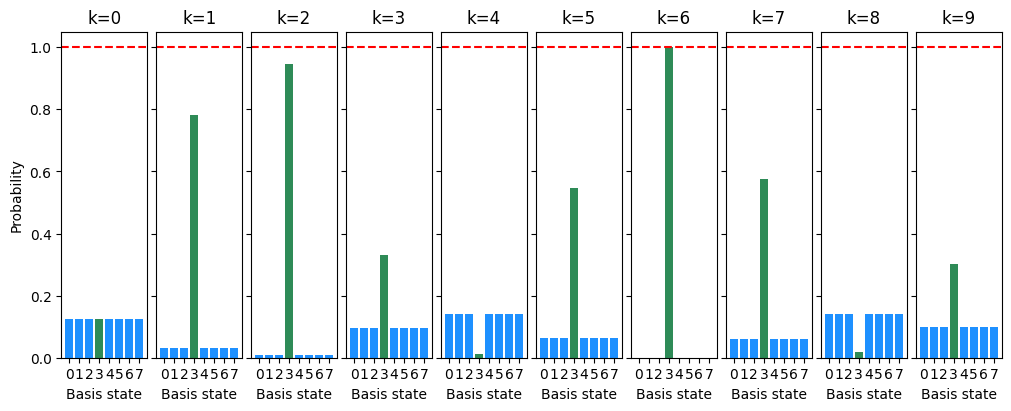

In [45]:
def grover(k):
    circuit = QuantumCircuit(3)
    initialize_superposition(circuit)
    # ---YOUR CODE HERE---
    for _ in range(k):
        oracle(circuit)              # flip the sign of the target |3>
        diffusion_operator(circuit)  # reflect about |psi_0>: together a rotation by 2*theta towards |3>
    # --------------------
    return Statevector.from_instruction(circuit).probabilities()

assert np.allclose(grover(1), [.03125, .03125, .03125, .78125, .03125, .03125, .03125, .03125]), "Incorrect output for Grover with k=1."
assert np.allclose(grover(2), [.0078125, .0078125, .0078125, .9453125, .0078125, .0078125, .0078125, .0078125]), "Incorrect output for Grover with k=2."

fig, ax = plt.subplots(nrows=1, ncols=10, figsize=(10, 4), sharey=True)
for k in range(10):
    ax[k].set_title(f'k={k}')
    probabilities = grover(k)
    colors = ['dodgerblue'] * 8
    colors[3] = 'seagreen'
    ax[k].bar(range(8), probabilities, color=colors)
    ax[k].set_xticks(range(8))
    ax[k].set_xlabel('Basis state')
    ax[k].axhline(y=1.0, color='r', linestyle='--')
ax[0].set_ylabel('Probability')
plt.tight_layout(pad=0.3)

<div style="max-width: 1200px; margin: auto; border: 1px solid #004791; border-left: 6px solid #004791; border-radius: 6px; padding: 0.8em 1em; background-color: #1b1b1bff; color: #eee;">

### Question B3.2

Why does the output probability of the target state not reach exactly 1?

</div>

**Answer**: Because each application of the Grover operator rotates the state by a fixed angle $2\theta \approx 41.4°$, and we can only apply it a whole number of times. After $k$ applications the state is at the angle $(2k+1)\theta$ from the axis of the wrong states, and the probability of the target is $\sin^2\big((2k+1)\theta\big)$. This is exactly 1 only if the state lands exactly on the target axis, i.e. $(2k+1)\theta = 90°$ (or $270°$, $450°$, ...).

For $n=3$ we have $\theta \approx 20.7°$, so the angles we can reach are $20.7°, 62.1°, 103.5°, 144.9°, 186.3°, 227.8°, 269.2°, \ldots$, and none of them is exactly $90° + m \cdot 180°$. The best result in the first pass is $k=2$ ($103.5°$, $P \approx 0.945$). Later, $k=6$ gives $269.2°$, which is less than $1°$ from $270°$, so $P \approx 0.9998$: in the plot it looks like it touches 1, but it is still slightly below.

The error gets smaller for larger databases: the step $2\theta$ becomes smaller, and we can always stop within $\theta$ of the target axis, which gives a success probability of at least $\cos^2\theta = 1 - 1/N$.

<div style="max-width: 1200px; margin: auto; border: 1px solid #004791; border-left: 6px solid #004791; border-radius: 6px; padding: 0.8em 1em; background-color: #1b1b1bff; color: #eee;">

### Question B3.3
If implemented correctly, the probability of measuring the target state appears to increase and decrease periodically as we apply the Grover operator more times. Explain why we observe this behavior.

</div>

**Answer**: The Grover operator is a rotation by $2\theta$ in the plane spanned by $\vert \phi\rangle$ and $\vert \phi^\perp\rangle$, and it always rotates in the same direction: it does not "know" when it has reached the target. After passing $\vert \phi\rangle$ it keeps rotating and moves away from it, then towards $-\vert \phi^\perp\rangle$, then $-\vert \phi\rangle$, and so on around the circle. The probability of measuring the target is

$$P(k) = \sin^2\big((2k+1)\theta\big),$$

which is periodic in $k$. The sign of the amplitude does not matter for the probability, so $P(k)$ repeats every half turn, i.e. every $\pi/(2\theta) \approx 4.3$ iterations for $n=3$. This is what we see in the plot: maxima at $k = 2$ and $k = 6$, and minima at $k = 4$ and $k = 8$, where the state is almost aligned with $\pm\vert \phi^\perp\rangle$.

(At $k=6$ the probability is even higher, $\approx 0.9998$, because $13\theta \approx 269.2°$ happens to be very close to $270°$. But it costs three times as many oracle calls as $k=2$, and this lucky alignment does not happen in general.)

This is why Grover's algorithm must stop after the right number of iterations: applying the operator more times does not help, and it can make the result much worse.